# Iterated Prisoner's Dilemma: Population Dynamics

The 2008 experiment: 175 agents, 25 for each of seven strategies. In each generation every agent plays a
200-move match against every other agent; then the next generation is drawn so that each strategy's share of the
population equals its share of all points scored. Strategies that score well multiply, and the opponents everyone
faces change with them.

This notebook replays that experiment with the rewritten code, compares it with the 2008 record in
`resources/`, and then lets the five classic strategies and noisy play into the population. The strategies and
the head-to-head scores are in `strategy-tournament.ipynb`.

**Running it.** The notebook takes about a minute and a half, most of it the two 600-agent runs at the end. The
code is `prisoners_dilemma.evolution`: `evolve(start, generations, rounds, pairing, payoff, noise, rng)` runs the
population game from a `{strategy: agents}` mapping and returns the agents per generation (`population`), the
points behind them (`points`) and the `shares`; `replicator(matrix, shares, generations)` is the
infinite-population version. Every random step takes `rng`, so reruns reproduce the saved outputs.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))  # project root, so prisoners_dilemma imports without installing
from prisoners_dilemma import evolution, plotting, strategies, tournament

plotting.style()
ORIGINAL = [s.name for s in strategies.ORIGINAL]
ALL = list(strategies.STRATEGIES)
START_2008 = {n: 25 for n in ["T4TDefect", "Random", "T4T", "AvgT4T", "Defect", "Pred1", "T4TForgive"]}

## The 2008 record

`resources/poprecord.csv` holds the population after each of the 40 generations, as alternating rows of
strategy names and counts (a strategy drops out of the header once it is extinct).

In [2]:
def read_2008_record(path):
    lines = [line.split("\t") for line in Path(path).read_text().split("\n") if line.strip()]
    rows = [dict(zip(names, map(int, counts))) for names, counts in zip(lines[::2], lines[1::2])]
    table = pd.DataFrame([START_2008] + rows).fillna(0).astype(int)[list(START_2008)]
    return table.rename_axis("generation")


record_2008 = read_2008_record("../resources/poprecord.csv")
record_2008.sum(axis=1).iloc[[0, 1, 2, 3, 10, 20, 30, 40]].rename("agents")

generation
0     175
1     175
2     175
3     176
10    178
20    181
30    191
40    201
Name: agents, dtype: int64

The population was meant to stay at 175 but grew to 201. The 2008 code rounded each strategy's new count
on its own (`int(round(share * n))`), so the counts did not have to add up to the old total, and Python 2's
`round` sends halves up, so the drift was mostly upward. The new code apportions whole agents with the
largest-remainder method, which always keeps the total.

## Replaying 2008

In [3]:
ev = evolution.evolve(START_2008, generations=40, rng=1)
pd.concat({"2008": record_2008.iloc[1:4], "2026": ev.population.iloc[1:4]}, axis=1).T

generation        1   2   3
2008 T4TDefect   24  22  20
     Random      25  24  23
     T4T         28  30  32
     AvgT4T      30  35  40
     Defect      16  10   6
     Pred1       24  23  21
     T4TForgive  28  31  34
2026 T4TDefect   24  22  20
     Random      25  24  23
     T4T         28  30  32
     AvgT4T      30  35  40
     Defect      16  10   5
     Pred1       24  23  21
     T4TForgive  28  31  34

The first two generations agree agent for agent, and the third differs only by the agent the 2008
rounding added. After that the random strategies' luck and the drift move the two runs apart, but they tell the
same story:

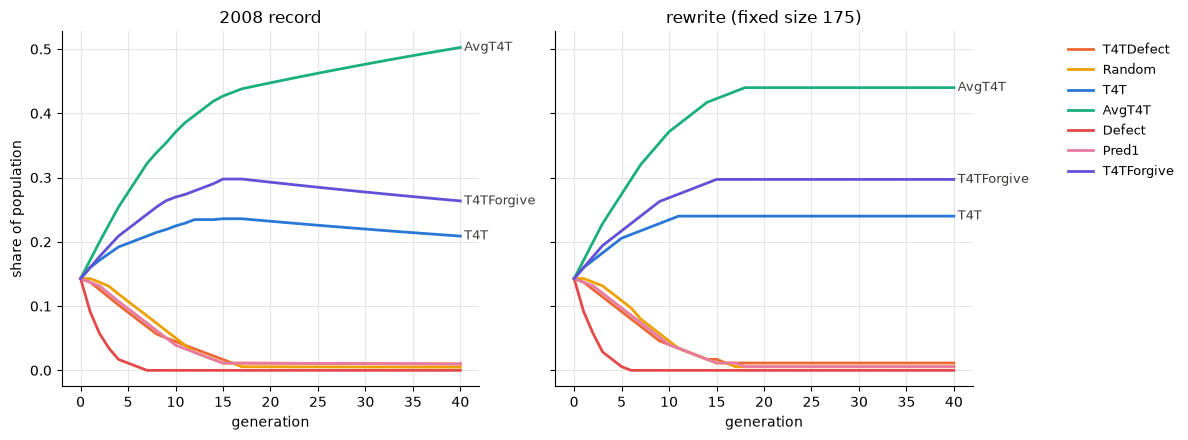

In [4]:
shares_2008 = record_2008.div(record_2008.sum(axis=1), axis=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, shares, title in [(axes[0], shares_2008, "2008 record"), (axes[1], ev.shares, "rewrite (fixed size 175)")]:
    plotting.plot_lines(shares, ax, label_min=0.05, legend=False)
    ax.set_title(title)
    ax.set_xlabel("generation")
axes[0].set_ylabel("share of population")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.2, 1), frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

Final shares after 40 generations:

In [5]:
pd.DataFrame({"2008": shares_2008.iloc[-1], "2026": ev.shares.iloc[-1]}).sort_values("2026", ascending=False).round(3)

,2008,2026
AvgT4T,0.502,0.440
T4TForgive,0.264,0.297
T4T,0.209,0.240
T4TDefect,0.010,0.011
Random,0.005,0.006
Pred1,0.010,0.006
Defect,0.000,0.000


Defect is gone within about 6 generations: it feeds on Random, Pred1 and T4TDefect, and dies with them.
Then the strategies that exploit or misread cooperators (Pred1, Random, T4TDefect) shrink to a few agents,
and the population settles into three cooperative strategies that score 600 against each other:
AvgT4T with 44%, then T4TForgive with 30% and T4T with 24%.

AvgT4T leads because it answers T4TDefect's occasional defection by its average, not by echoing it (571 points
per match against T4TDefect, where T4T gets about 325). Once the other strategies are nearly gone, every match
between the survivors is mutual cooperation, so their shares freeze, as they do in the rewrite from generation
18. In the 2008 record they keep moving, and AvgT4T creeps up to 50%: that movement is the rounding drift
alone.

## The infinite-population limit

The same rule for a population too large to count in agents: each share is multiplied by the strategy's
average points against the current mix, relative to the population's average (discrete replicator dynamics).
It needs only the head-to-head score matrix.

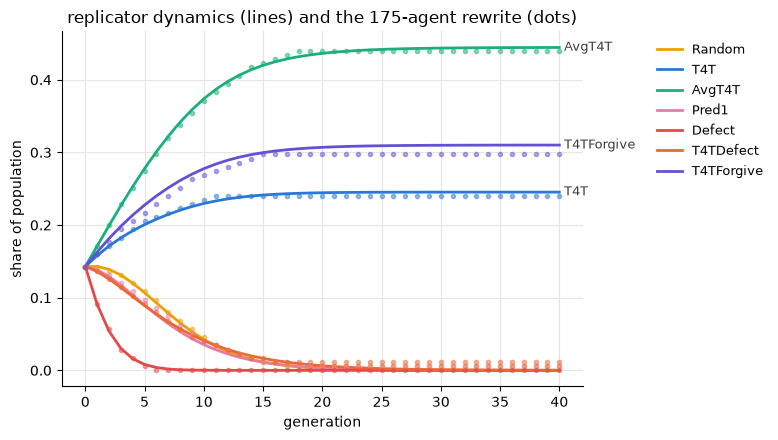

In [6]:
matrix = tournament.score_matrix(tournament.head_to_head(ORIGINAL, rng=0))
rep = evolution.replicator(matrix, generations=40)

fig, ax = plt.subplots(figsize=(8, 4.5))
plotting.plot_lines(rep, ax, label_min=0.05)
for name in ORIGINAL:
    ax.plot(ev.shares.index, ev.shares[name], "o", ms=3, color=plotting.color(name), alpha=0.5)
ax.set_xlabel("generation")
ax.set_ylabel("share of population")
ax.set_title("replicator dynamics (lines) and the 175-agent rewrite (dots)")
plt.tight_layout()
plt.show()

The replicator equation follows the agent simulation closely: the finite population adds rounding and the
luck of the random strategies, not a different outcome. Note that the 2008 rule includes an agent's matches
against its own strategy but not against itself, a small difference at 25 agents per strategy.

## Random pairing

The 2008 code had a second tournament: each generation the agents are shuffled and paired off, so each plays
one match instead of 174. Fewer matches means much more luck in each generation.

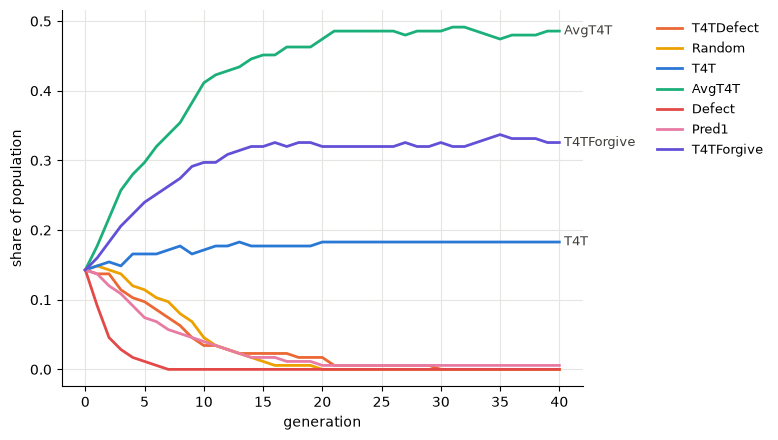

In [7]:
ev_random = evolution.evolve(START_2008, generations=40, pairing="random", rng=2)
fig, ax = plt.subplots(figsize=(8, 4.5))
plotting.plot_lines(ev_random.shares, ax, label_min=0.05)
ax.set_xlabel("generation")
ax.set_ylabel("share of population")
plt.tight_layout()
plt.show()

The ordering is the same; the curves are rougher. In 2008 this version had one more problem: an
`IndexError` ended each generation's pairing loop, and the same `try` block would also have swallowed an
`IndexError` from inside a match.

## All twelve strategies, with and without mistakes

The twelve strategies in equal shares, without mistakes and with every move flipped with probability 0.05.
The curves are the infinite-population limit, from each condition's head-to-head matrix.

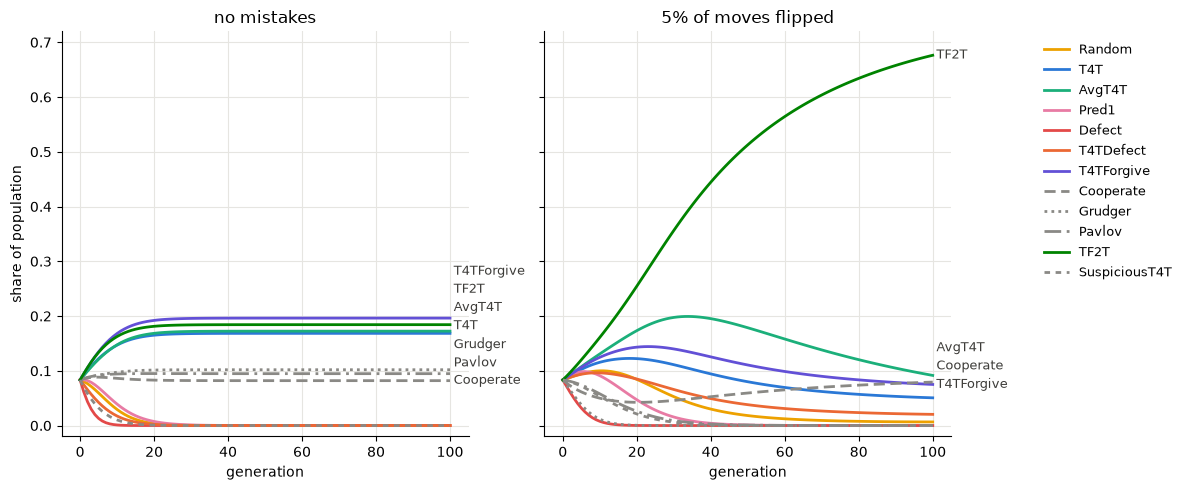

In [8]:
rep_clean = evolution.replicator(tournament.score_matrix(tournament.head_to_head(ALL, rng=0)), generations=100)
rep_noisy = evolution.replicator(tournament.score_matrix(tournament.head_to_head(ALL, noise=0.05, rng=0)),
                                 generations=100)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].set_ylim(-0.02, 0.72)  # fixed first, so the end labels are spaced for the shared axis
for ax, shares, title in [(axes[0], rep_clean, "no mistakes"), (axes[1], rep_noisy, "5% of moves flipped")]:
    plotting.plot_lines(shares, ax, label_min=0.06, legend=False)
    ax.set_title(title)
    ax.set_xlabel("generation")
axes[0].set_ylabel("share of population")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.2, 1), frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

Shares after 100 generations:

In [9]:
pd.DataFrame({"no mistakes": rep_clean.iloc[-1], "5% flipped": rep_noisy.iloc[-1]}
             ).sort_values("no mistakes", ascending=False).round(3)

,no mistakes,5% flipped
player,,
T4TForgive,0.196,0.075
TF2T,0.184,0.676
AvgT4T,0.172,0.092
T4T,0.168,0.051
Grudger,0.102,0.000
Pavlov,0.095,0.000
Cooperate,0.082,0.079
Pred1,0.000,0.000
Random,0.000,0.007


### The same with 600 agents

A finite population changes in whole agents: a strategy with c agents moves only when its points differ from
the population average by more than about 1/(2c), so with too few agents per strategy the small differences
between the nice strategies are rounded away and the counts stall. Fifty agents of each strategy (600 in all)
bring that threshold down to about 1%. The two runs take about a minute; they run in parallel processes. The thin
lines are the infinite-population curves from above.

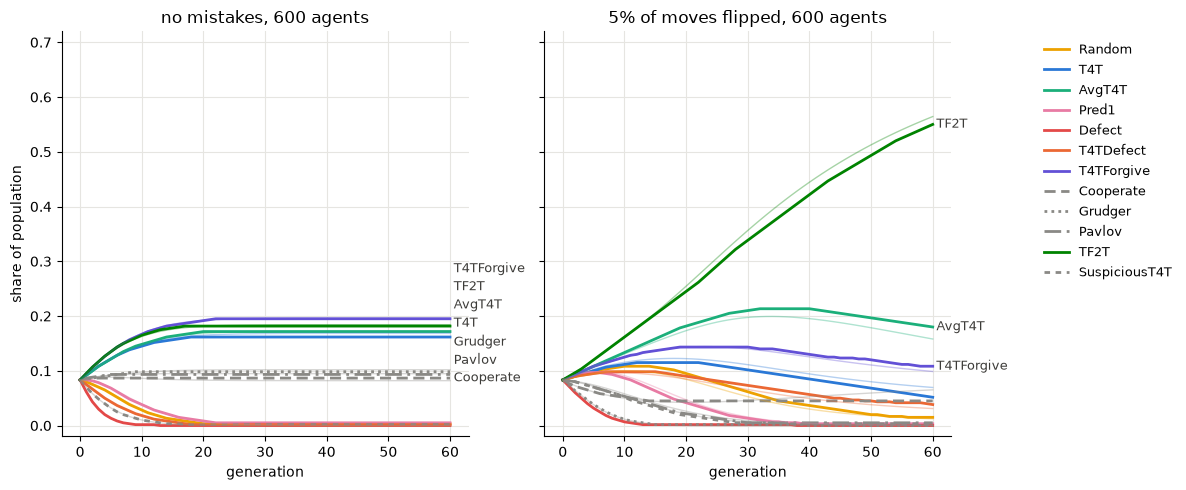

In [10]:
from concurrent.futures import ProcessPoolExecutor

AGENTS_PER_STRATEGY, GENERATIONS = 50, 60
START_ALL = {n: AGENTS_PER_STRATEGY for n in ALL}
with ProcessPoolExecutor() as pool:
    runs = [pool.submit(evolution.evolve, START_ALL, GENERATIONS, noise=noise, rng=seed)
            for noise, seed in [(0.0, 3), (0.05, 4)]]
    ev_clean, ev_noisy = (r.result() for r in runs)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].set_ylim(-0.02, 0.72)
for ax, e, r, title in [(axes[0], ev_clean, rep_clean, "no mistakes"),
                        (axes[1], ev_noisy, rep_noisy, "5% of moves flipped")]:
    plotting.plot_lines(e.shares, ax, label_min=0.06, legend=False)
    for name in ALL:
        ax.plot(r.index[:GENERATIONS + 1], r[name].iloc[:GENERATIONS + 1], color=plotting.color(name),
                linewidth=1, alpha=0.35)
    ax.set_title(f"{title}, {len(ALL) * AGENTS_PER_STRATEGY} agents")
    ax.set_xlabel("generation")
axes[0].set_ylabel("share of population")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.2, 1), frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

Shares after 60 generations, agents next to the infinite population:

In [11]:
pd.DataFrame({"agents, no mistakes": ev_clean.shares.iloc[-1], "agents, 5% flipped": ev_noisy.shares.iloc[-1],
              "infinite, no mistakes": rep_clean.iloc[GENERATIONS], "infinite, 5% flipped": rep_noisy.iloc[GENERATIONS]}
             ).sort_values("agents, no mistakes", ascending=False).round(3)

,"agents, no mistakes","agents, 5% flipped","infinite, no mistakes","infinite, 5% flipped"
T4TForgive,0.195,0.108,0.196,0.099
TF2T,0.182,0.550,0.184,0.564
AvgT4T,0.172,0.180,0.172,0.158
T4T,0.162,0.052,0.168,0.070
Grudger,0.098,0.000,0.102,0.000
Pavlov,0.093,0.005,0.095,0.000
Cooperate,0.087,0.045,0.082,0.065
Pred1,0.005,0.003,0.000,0.000
Random,0.003,0.015,0.000,0.012
T4TDefect,0.002,0.038,0.000,0.031


- **Without mistakes**, every strategy that defects first (Defect, Pred1, Random, T4TDefect,
  SuspiciousT4T) dies out, and the seven nice strategies keep the shares they had won by then. Once only nice
  strategies remain, every match is mutual cooperation and nobody gains: the more forgiving retaliators
  (T4TForgive, TF2T) end slightly ahead because they lost least to the noisy and suspicious strategies early on.
- **With 5% mistakes**, TF2T takes over (56% after 60 generations, 68% after 100, and still rising). AvgT4T grows at first,
  then declines as the exploiters it was beating disappear. Grudger and Pavlov die out: a single mistake turns
  Grudger into a defector for the rest of the match, and Pavlov is exploited by the random strategies.
  Cooperate survives on the cooperation of the others.
- The 600-agent runs follow the infinite population to within a couple of percentage points after 60
  generations. The random strategies' luck shows mostly in the noisy run, where AvgT4T holds on a little longer.

## Summary

- Scoring well is not the same as winning matches: Defect never loses a match and always dies first.
- In every population here the winners are nice (never the first to defect), retaliate, and forgive. How much
  forgiveness pays depends on how often players make mistakes.
- The 2008 results stand, but the 2008 population grew from 175 to 201 agents by rounding, which kept
  AvgT4T's share climbing to 50% after the matches had stopped changing anything; with a fixed population it
  settles at 44%.